## 01 Подготовка и воспроизводимое разбиение


In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import stats

cwd = Path.cwd()
PROJECT = next(p for p in [cwd, cwd.parent, cwd / "student-performance-project"]
               if (p / "data/raw/StudentPerformanceFactors.csv").exists())
sys.path.insert(0, str(PROJECT))
from src.split_data import split_data
FIG = PROJECT / "reports/figures"
TAB = PROJECT / "reports/tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11})
pd.set_option("display.max_rows", 30)
pd.set_option("display.width", 110)
pd.set_option("display.max_colwidth", 28)
print(split_data(PROJECT).drop(columns="sha256").to_string(index=False))
manifest = json.loads((PROJECT / "data/manifests/split_manifest.json").read_text())
print("SEED:", manifest["seed"])
print("Всего строк:", manifest["raw_rows"])
print("SHA-256 исходника:", manifest["raw_sha256"])

                      file  rows
        data/base/base.csv  3964
data/incoming/batch_01.csv   661
data/incoming/batch_02.csv   661
data/incoming/batch_03.csv   661
data/incoming/batch_04.csv   660
SEED: 42
Всего строк: 6607
SHA-256 исходника: e8df8c4148ef83fb295ca1c092f2c6ee15272c0a8e3018b769a788ab50e96e97


## 02 Структура исходной части


In [2]:
df = pd.read_csv(PROJECT / "data/base/base.csv")
num = df.select_dtypes(include="number").columns.tolist()
cat = [c for c in df.columns if c not in num]
schema = pd.DataFrame({"feature": df.columns,
                       "type": ["integer" if c in num else "category" for c in df.columns],
                       "unique": df.nunique().values,
                       "missing": df.isna().sum().values})
schema.to_csv(TAB / "schema.csv", index=False)
print("EDA только на исходной части:", df.shape)
print("Числовых столбцов:", len(num), "Категориальных:", len(cat))
print(schema.to_string(index=False))
print("\nПервые строки:")
print(df[["Hours_Studied", "Attendance", "Previous_Scores", "Exam_Score"]].head().to_string(index=False))

EDA только на исходной части: (3964, 20)
Числовых столбцов: 7 Категориальных: 13
                   feature     type  unique  missing
             Hours_Studied  integer      41        0
                Attendance  integer      41        0
      Parental_Involvement category       3        0
       Access_to_Resources category       3        0
Extracurricular_Activities category       2        0
               Sleep_Hours  integer       7        0
           Previous_Scores  integer      51        0
          Motivation_Level category       3        0
           Internet_Access category       2        0
         Tutoring_Sessions  integer       9        0
             Family_Income category       3        0
           Teacher_Quality category       3       49
               School_Type category       2        0
            Peer_Influence category       3        0
         Physical_Activity  integer       7        0
     Learning_Disabilities category       2        0
  Parental_Educati

## 03 Проверка качества данных


In [3]:
missing = df.isna().sum().loc[lambda s: s > 0]
quality = missing.rename("missing").to_frame()
quality["percent"] = (100 * quality["missing"] / len(df)).round(3)
print("Пропуски:\n", quality.to_string())
print("Полных дубликатов:", df.duplicated().sum())
invalid = ~df["Exam_Score"].between(0, 100)
print("Оценок вне 0..100:", int(invalid.sum()))
print(df.loc[invalid, ["Hours_Studied", "Attendance", "Exam_Score"]].to_string(index=False))
outliers = []
for col in num:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    count = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    outliers.append({"feature": col, "min": df[col].min(), "max": df[col].max(),
                     "IQR_outliers": int(count)})
outliers = pd.DataFrame(outliers)
print("\nДиапазоны и выбросы IQR:\n", outliers.to_string(index=False))
quality.to_csv(TAB / "missing.csv")
outliers.to_csv(TAB / "outliers.csv", index=False)
# Недостоверную целевую метку не исправляем и не заполняем.
valid = df.loc[~invalid].copy()
print("Для анализа зависимостей и гипотез:", len(valid), "строк")

Пропуски:
                           missing  percent
Teacher_Quality                49    1.236
Parental_Education_Level       53    1.337
Distance_from_Home             42    1.060
Полных дубликатов: 0
Оценок вне 0..100: 1
 Hours_Studied  Attendance  Exam_Score
            27          98         101

Диапазоны и выбросы IQR:
           feature  min  max  IQR_outliers
    Hours_Studied    1   44            27
       Attendance   60  100             0
      Sleep_Hours    4   10             0
  Previous_Scores   50  100             0
Tutoring_Sessions    0    8           253
Physical_Activity    0    6             0
       Exam_Score   55  101            41
Для анализа зависимостей и гипотез: 3963 строк


## 04 Целевая переменная и распределения


count    3963.000
mean       67.318
std         3.926
min        55.000
25%        65.000
50%        67.000
75%        70.000
max        99.000

Баланс условных классов:
                           count  percent
Не в зоне риска            3121   78.753
В зоне риска (балл < 65)    842   21.247
Сохранены target.png и distributions.png


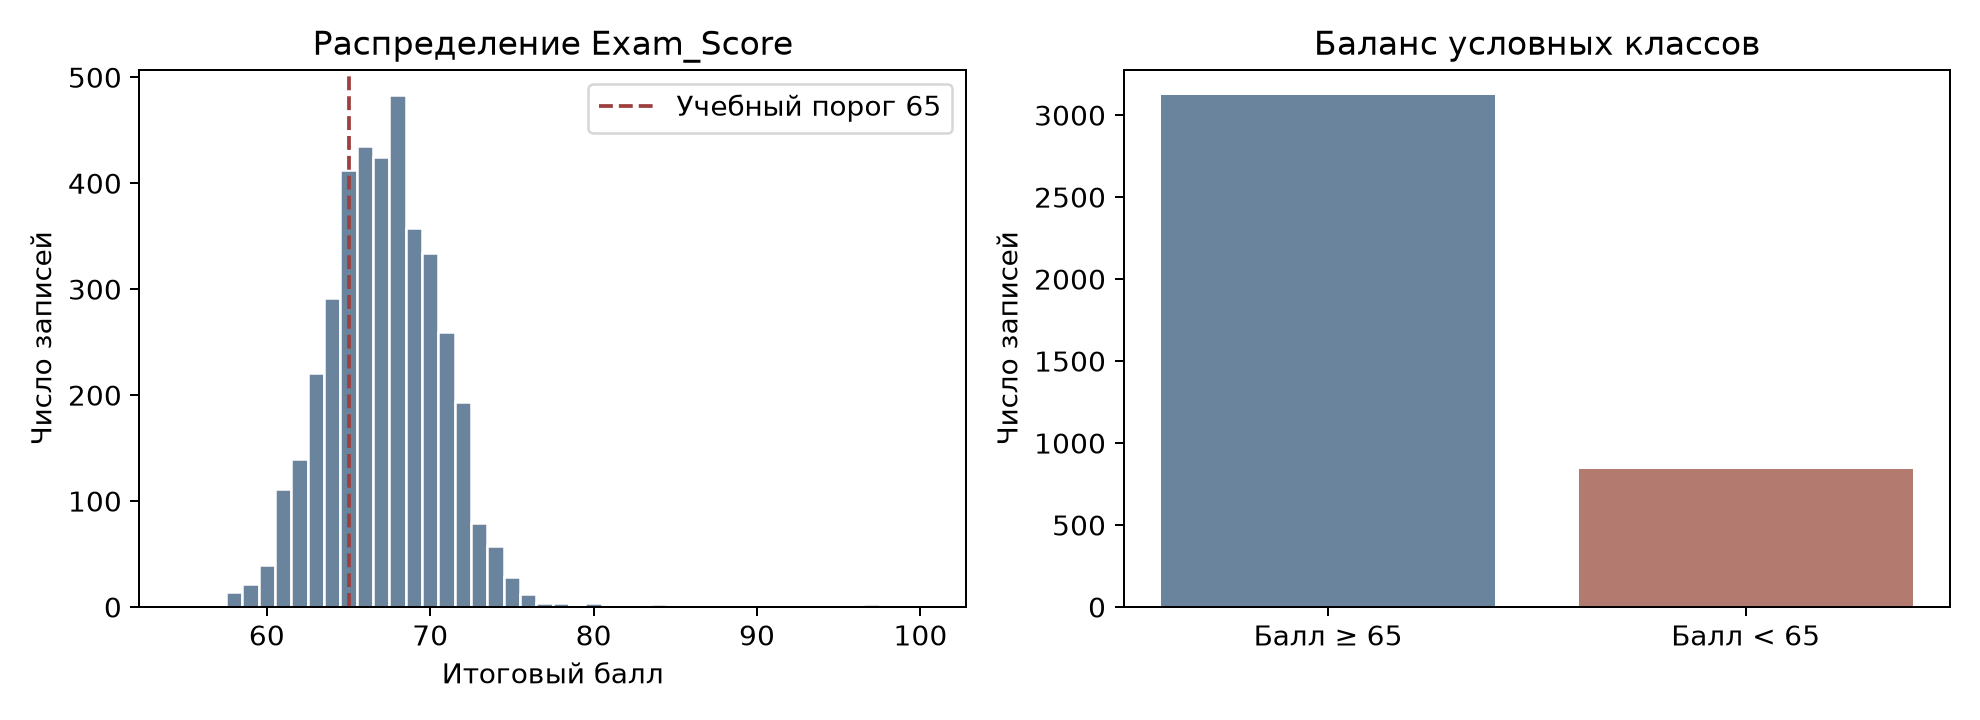

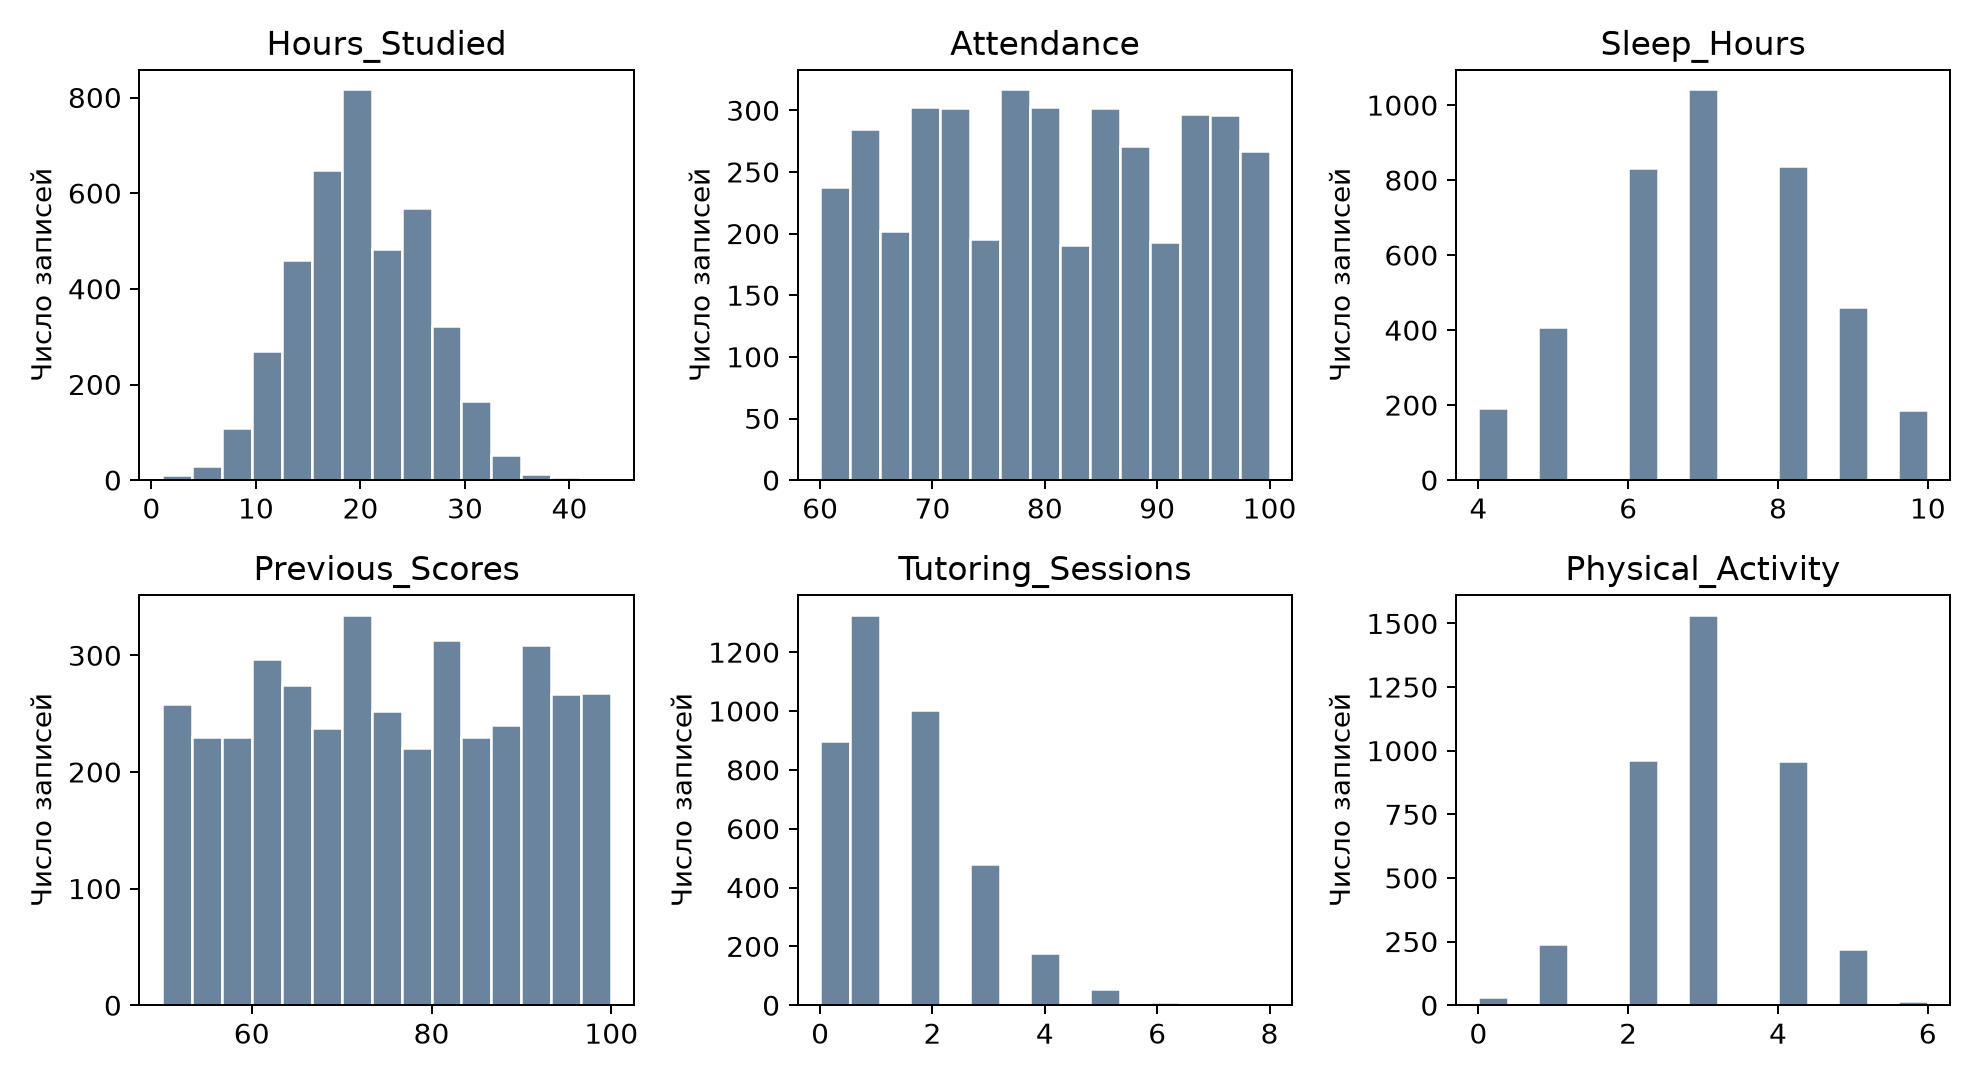

In [4]:
print(valid["Exam_Score"].describe().round(3).to_string())
# Порог 65 - учебное определение риска, а не норматив университета.
risk = valid["Exam_Score"].lt(65)
balance = pd.DataFrame({"count": risk.value_counts().reindex([False, True], fill_value=0)})
balance.index = ["Не в зоне риска", "В зоне риска (балл < 65)"]
balance["percent"] = (100 * balance["count"] / len(valid)).round(3)
print("\nБаланс условных классов:\n", balance.to_string())
balance.to_csv(TAB / "risk_balance.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(valid["Exam_Score"], bins=np.arange(54.5, 101.5, 1), color="#6b849d", edgecolor="white")
axes[0].axvline(65, color="#9d3f3f", linestyle="--", label="Учебный порог 65")
axes[0].set(xlabel="Итоговый балл", ylabel="Число записей", title="Распределение Exam_Score")
axes[0].legend()
axes[1].bar(["Балл ≥ 65", "Балл < 65"], balance["count"], color=["#6b849d", "#b37b70"])
axes[1].set(ylabel="Число записей", title="Баланс условных классов")
fig.tight_layout(); fig.savefig(FIG / "target.png", dpi=180); plt.close(fig)
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, col in zip(axes.flat, [c for c in num if c != "Exam_Score"]):
    ax.hist(valid[col], bins=15, color="#6b849d", edgecolor="white")
    ax.set(title=col, ylabel="Число записей")
fig.tight_layout(); fig.savefig(FIG / "distributions.png", dpi=180); plt.close(fig)
print("Сохранены target.png и distributions.png")
from IPython.display import display, Image
display(Image(filename=str(FIG / "target.png")))
display(Image(filename=str(FIG / "distributions.png")))

## 05 Связь признаков и целевой переменной


Корреляции с итоговым баллом:
Attendance           0.5729
Hours_Studied        0.4406
Tutoring_Sessions    0.1525
Previous_Scores      0.1520
Physical_Activity    0.0261
Sleep_Hours         -0.0013

Максимальная абсолютная корреляция между числовыми предикторами:
Attendance         Previous_Scores      0.0304
Sleep_Hours        Physical_Activity    0.0232
Tutoring_Sessions  Physical_Activity    0.0202
Attendance         Physical_Activity    0.0191
Hours_Studied      Tutoring_Sessions    0.0163

Доступ к ресурсам:
                      count    mean  median
Access_to_Resources                       
High                  1170  68.153    68.0
Low                    787  66.386    66.0
Medium                2006  67.196    67.0


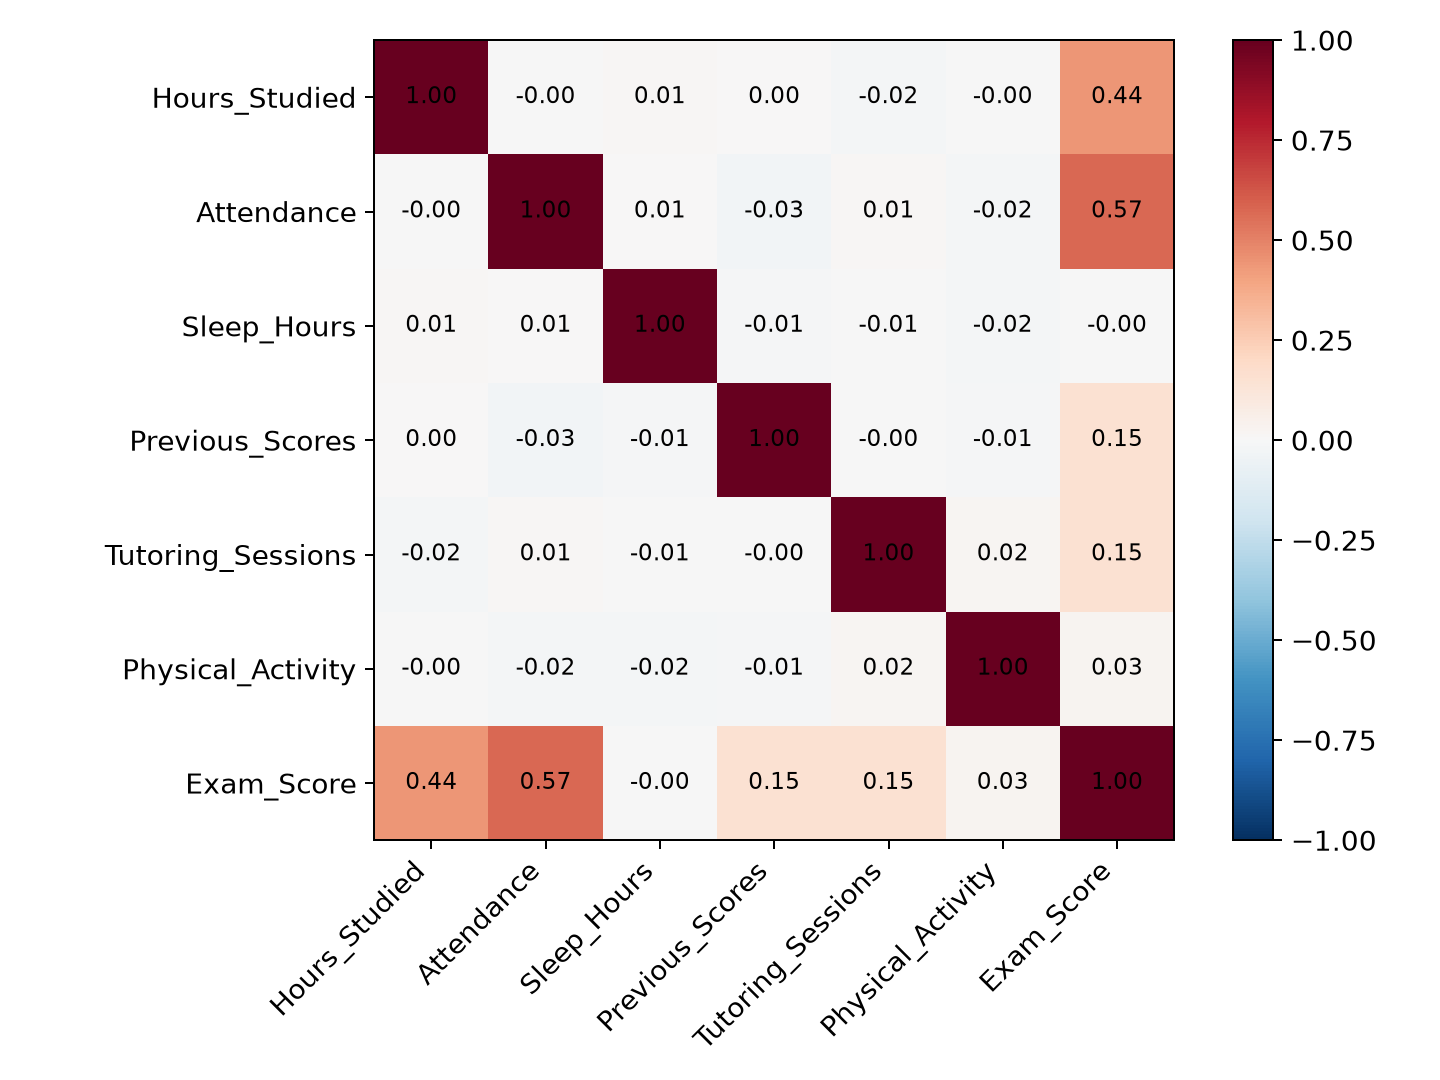

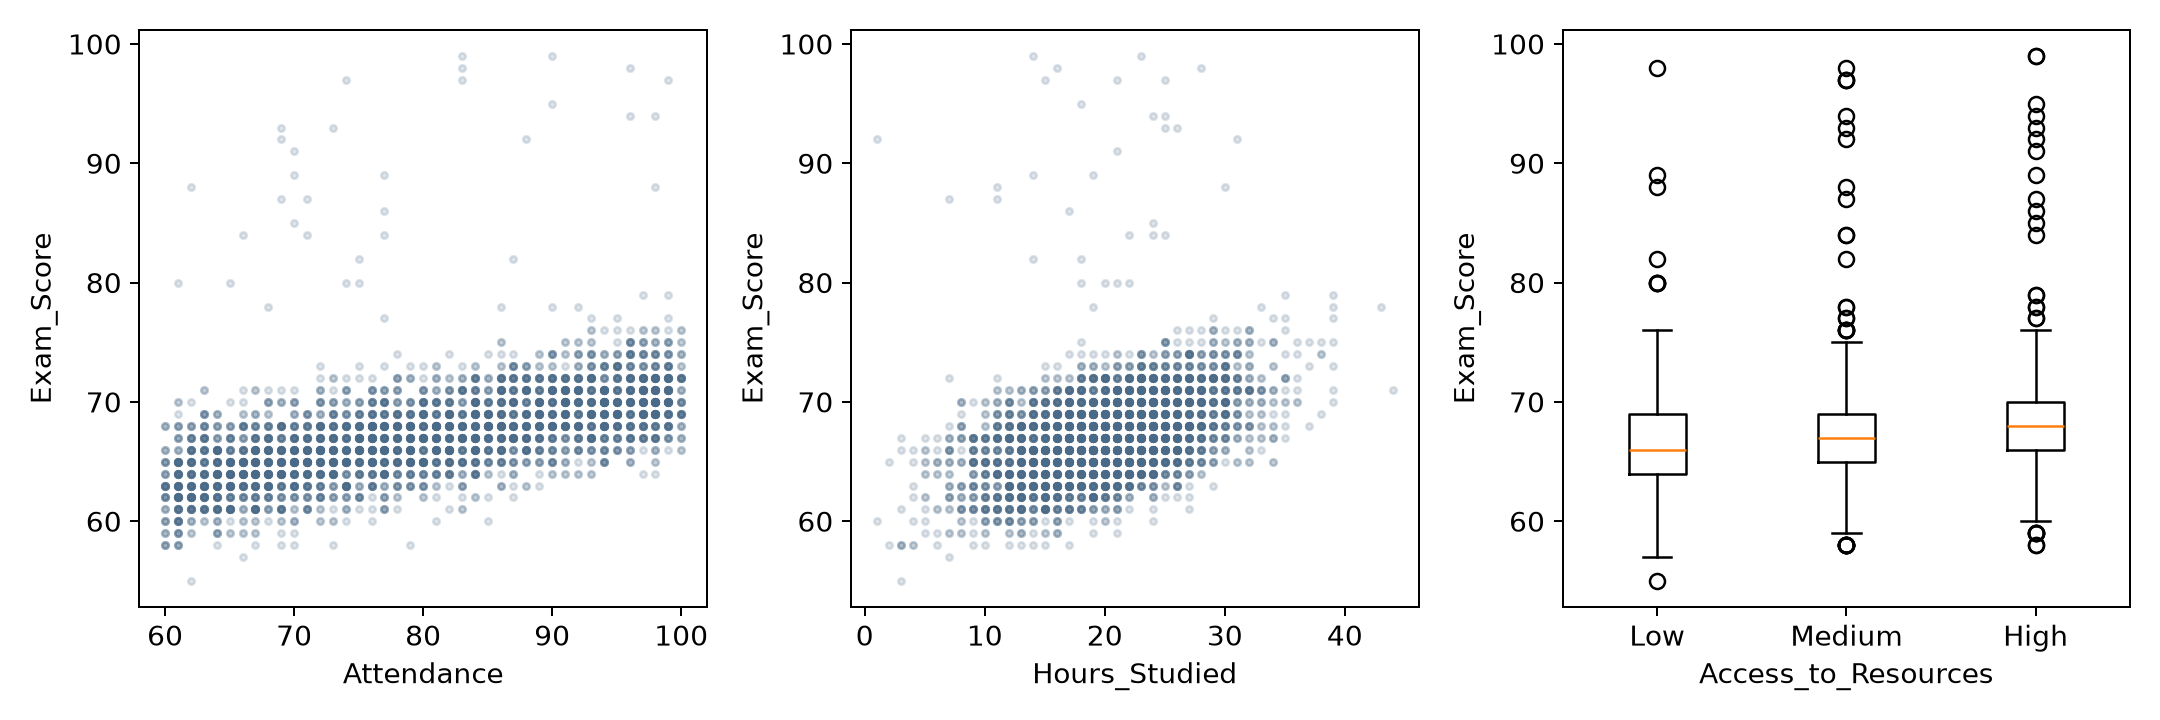

In [5]:
corr = valid[num].corr()
print("Корреляции с итоговым баллом:")
print(corr["Exam_Score"].drop("Exam_Score").sort_values(ascending=False).round(4).to_string())
pairs = corr.drop(index="Exam_Score", columns="Exam_Score")
pairs = pairs.where(np.triu(np.ones(pairs.shape), k=1).astype(bool)).stack()
print("\nМаксимальная абсолютная корреляция между числовыми предикторами:")
print(pairs.abs().sort_values(ascending=False).head(5).round(4).to_string())
groups = valid.groupby("Access_to_Resources")["Exam_Score"].agg(["count", "mean", "median"])
print("\nДоступ к ресурсам:\n", groups.round(3).to_string())
corr.to_csv(TAB / "correlations.csv")
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(num)), num, rotation=45, ha="right")
ax.set_yticks(range(len(num)), num)
for i in range(len(num)):
    for j in range(len(num)): ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax); fig.tight_layout(); fig.savefig(FIG / "correlations.png", dpi=180); plt.close(fig)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes[:2], ["Attendance", "Hours_Studied"]):
    ax.scatter(valid[col], valid["Exam_Score"], s=7, alpha=0.18, color="#496a88")
    ax.set(xlabel=col, ylabel="Exam_Score")
levels=["Low", "Medium", "High"]
axes[2].boxplot([valid.loc[valid["Access_to_Resources"].eq(v), "Exam_Score"] for v in levels], tick_labels=levels)
axes[2].set(xlabel="Access_to_Resources", ylabel="Exam_Score")
fig.tight_layout(); fig.savefig(FIG / "relationships.png", dpi=180); plt.close(fig)
from IPython.display import display, Image
display(Image(filename=str(FIG / "correlations.png")))
display(Image(filename=str(FIG / "relationships.png")))

## 06 Проверка предметных гипотез


In [6]:
tests = []
for name, col in [("H1 Посещаемость связана с баллом", "Attendance"),
                  ("H2 Время подготовки связано с баллом", "Hours_Studied"),
                  ("H3 Предыдущий результат связан с итогом", "Previous_Scores")]:
    result = stats.spearmanr(valid[col], valid["Exam_Score"])
    tests.append({"hypothesis": name, "statistic": result.statistic,
                  "p_value": result.pvalue, "method": "Spearman, two-sided"})
low = valid.loc[valid["Access_to_Resources"].eq("Low"), "Exam_Score"]
high = valid.loc[valid["Access_to_Resources"].eq("High"), "Exam_Score"]
test = stats.mannwhitneyu(high, low, alternative="two-sided")
delta = 2 * test.statistic / (len(high) * len(low)) - 1
tests.append({"hypothesis": "H4 Ресурсы High и Low связаны с разным результатом",
              "statistic": delta, "p_value": test.pvalue, "method": "Mann-Whitney; effect Cliff delta"})
tests = pd.DataFrame(tests)
tests["p_bonferroni"] = (tests["p_value"] * len(tests)).clip(upper=1)
tests["reject_H0_at_0.05"] = tests["p_bonferroni"].lt(0.05)
tests.to_csv(TAB / "hypotheses.csv", index=False)
for row in tests.to_dict("records"):
    print(row["hypothesis"])
    print(f'  эффект={row["statistic"]:.4f}; p={row["p_value"]:.3e}; '
          f'p_adj={row["p_bonferroni"]:.3e}; H0 отклонена={row["reject_H0_at_0.05"]}')
print(f"Среднее High={high.mean():.3f}; Low={low.mean():.3f}; разница={high.mean()-low.mean():.3f}")
print("Связи наблюдательные; причинность не установлена.")

H1 Посещаемость связана с баллом
  эффект=0.6746; p=0.000e+00; p_adj=0.000e+00; H0 отклонена=True
H2 Время подготовки связано с баллом
  эффект=0.4830; p=8.764e-231; p_adj=3.505e-230; H0 отклонена=True
H3 Предыдущий результат связан с итогом
  эффект=0.1675; p=2.541e-26; p_adj=1.016e-25; H0 отклонена=True
H4 Ресурсы High и Low связаны с разным результатом
  эффект=0.2825; p=1.745e-26; p_adj=6.981e-26; H0 отклонена=True
Среднее High=68.153; Low=66.386; разница=1.767
Связи наблюдательные; причинность не установлена.


## 07 Проверки качества и итоговый протокол


In [7]:
bounds = {"Hours_Studied": (0, 168), "Attendance": (0, 100),
          "Sleep_Hours": (0, 24), "Previous_Scores": (0, 100),
          "Tutoring_Sessions": (0, 31), "Physical_Activity": (0, 168)}
print("Контроль физических и предметных границ:")
for col, (lo, hi) in bounds.items():
    print(col, int((~df[col].between(lo, hi)).sum()))
print("Максимальная доля пропусков:", round(df.isna().mean().max() * 100, 3), "%")
summary = {"base_rows": len(df), "valid_rows": len(valid),
           "invalid_target": int(invalid.sum()), "duplicates": int(df.duplicated().sum()),
           "missing": {c: int(n) for c, n in missing.items()},
           "target": valid["Exam_Score"].describe().to_dict(),
           "risk_count": int(risk.sum()), "risk_share": float(risk.mean()),
           "target_corr": corr["Exam_Score"].to_dict(),
           "max_predictor_corr": float(pairs.abs().max()),
           "hypotheses": tests.to_dict("records"),
           "resource_means": {"High": float(high.mean()), "Low": float(low.mean())},
           "source_sha256": manifest["raw_sha256"]}
(PROJECT / "reports/eda_summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print("Сохранены таблицы, рисунки и reports/eda_summary.json")
print("Порции incoming не использовались для EDA и выбора признаков.")

Контроль физических и предметных границ:
Hours_Studied 0
Attendance 0
Sleep_Hours 0
Previous_Scores 0
Tutoring_Sessions 0
Physical_Activity 0
Максимальная доля пропусков: 1.337 %
Сохранены таблицы, рисунки и reports/eda_summary.json
Порции incoming не использовались для EDA и выбора признаков.
